# Demonstrations

Demonstrative experiments to show:
1) The importance of evaluating prevalence for each homogeneous population individually
2) The value add of the method, in terms of increased coverage and confidence in estimates

In [1]:
from pathlib import Path

import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
import seaborn as sns

from gene_prevalence import BernoulliPrevalenceModel

# instatiate random number generator with fixed seed for reproducibility
rng = np.random.default_rng(seed=9481)

# significance level for confidence intervals
ci_alpha = 0.05

In [2]:
# set aesthetic parameters

line_color = '#0F0A0A'    # dark

neutral_color = '#E0E0E0'

# thursday
accent_colors = ['#9B5DE5', '#FFAC69', '#00C9AE', '#FD3F92', '#0F0A0A', 
                 '#959AB1', '#FFDB66', '#63B9FF','#FFB1CA', '#4F1DD7']

style = {'axes.edgecolor': line_color,
         'axes.labelcolor': line_color,
         'text.color': line_color,
         'xtick.color': line_color,
         'ytick.color': line_color,
         'font.family': 'Helvetica',
         'font.Helvetica': ['Helvetica']}

palette = sns.color_palette(accent_colors)

sns.set_context('talk', rc={'lines.linewidth': 2})
sns.set_palette(palette)
sns.set_style('ticks', style)

plt.rcParams['legend.frameon'] = False
plt.rcParams['axes.spines.left'] = True
plt.rcParams['axes.spines.right'] = False
plt.rcParams['axes.spines.top'] = False
plt.rcParams['axes.spines.bottom'] = True
plt.rcParams['axes.facecolor'] = 'none'
plt.rcParams['figure.facecolor'] = 'none'
plt.rcParams['patch.linewidth'] = 0
plt.rcParams['patch.edgecolor'] = 'none'
plt.rcParams['savefig.dpi'] = 300

In [3]:
# Read in the full presence/absence data

# directory paths
project_root = Path.cwd().resolve().parent
data_dir = project_root / "data"

# presence/absence data
pa_df = pd.read_csv(
    data_dir / "pro_pangenome_presence_absence_data.csv",
    index_col=0,
).T

# metadata for the genomes in the clade-balanced dataset
genome_metadata_df = pd.read_csv(data_dir / "pro_pangenome_metadata.csv")
completeness_series = genome_metadata_df.set_index("genome")["completeness"] / 100

# identify most represented clade for each gene cluster
clade_df = pa_df.copy()
clade_df['clade'] = clade_df.index.map(genome_metadata_df.set_index('genome')['clade'])
most_repped_clade = clade_df.groupby('clade').sum().idxmax()

pa_df

gene_cluster_id,GC_00000001,GC_00000002,GC_00000003,GC_00000004,GC_00000005,GC_00000006,GC_00000007,GC_00000008,GC_00000009,GC_00000010,...,GC_00052849,GC_00052850,GC_00052851,GC_00052852,GC_00052853,GC_00052854,GC_00052855,GC_00052856,GC_00052857,GC_00052858
ProchlorococcusAC669I9,0,1,1,1,1,0,1,1,1,1,...,0,0,0,0,0,0,0,0,0,0
ProchlorococcusAC669J22,1,1,1,1,1,0,1,1,1,1,...,0,0,0,0,0,0,0,0,0,0
ProchlorococcusAC669O11,0,1,1,1,1,0,1,1,1,1,...,0,0,0,0,0,0,0,0,0,0
ProchlorococcusAC669K21,1,1,1,1,1,0,1,1,1,1,...,0,0,0,0,0,0,0,0,0,0
ProchlorococcusAC669K20,1,1,0,1,1,0,1,1,1,1,...,0,0,0,0,0,0,0,0,0,0
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
ProchlorococcusMIT1223,1,1,1,1,1,1,1,1,1,1,...,0,0,0,0,0,0,0,0,0,0
ProchlorococcusAG402N21,1,1,1,1,1,1,1,1,1,1,...,0,0,0,0,0,0,0,0,0,0
ProchlorococcusAG409P19,1,1,1,1,1,1,1,1,1,1,...,0,0,0,0,0,0,0,0,0,0
ProchlorococcusAG409D09,1,1,1,1,1,0,1,1,1,0,...,0,0,0,0,0,0,0,0,0,0


### Variable prevalences between clade subpopulations

Demonstration that gene prevalence values vary between clade subpopulations, but are relatively homogeneous within clade subpopulations

In [4]:
# evaluate predictions between clades and within the same clade

# define the sample size to evaluate
sample_size = 50

# pull out clade subpopulations and create random samples for each comparison
hlii_genomes = rng.permutation(
    genome_metadata_df.loc[genome_metadata_df['clade'] == 'HLII', 'genome'].to_numpy(copy=True)
)
lli_genomes = rng.permutation(
    genome_metadata_df.loc[genome_metadata_df['clade'] == 'LLI', 'genome'].to_numpy(copy=True)
)
samples = {
    'cross-clade': {
        'A': hlii_genomes[:sample_size],
        'B': lli_genomes[:sample_size]
    },
    'within-clade': {
        'A': hlii_genomes[:sample_size],
        'B': hlii_genomes[sample_size:2*sample_size]
    }
}

# fit model and compute confidence intervals for each sample
for subset in ['cross-clade', 'within-clade']:
    results = {}
    for sample in ['A', 'B']:
        genome_subset = samples[subset][sample]
        subset_df = pa_df.loc[genome_subset].copy()
        # fit prevalence model
        model = BernoulliPrevalenceModel(
            data=subset_df, 
            lambdas=completeness_series.loc[genome_subset], 
        )
        fit = model.fit(
            estimator="mle",
            interval_method="likelihood_ratio",
            alpha=ci_alpha,
            clip=True,
        )
        pi_hat = fit.prevalence
        ci_lower, ci_upper = fit.confidence_interval()
        results[f'pi_hat_{sample}'] = pi_hat
        results[f'ci_lower_{sample}'] = ci_lower
        results[f'ci_upper_{sample}'] = ci_upper
    # build results dataframe for this subset
    df = pd.DataFrame(results, index=pa_df.columns.copy())
    # remove gene clusters with zero prevalence in both samples
    df = df.loc[~((df['pi_hat_A'] == 0) & (df['pi_hat_B'] == 0))]
    # identify genes prevalence estimates that fall within the confidence interval 
    # of the other sample's prevalence estimate
    df['A_in_B'] = (df['pi_hat_A'] >= df['ci_lower_B']) & (df['pi_hat_A'] <= df['ci_upper_B'])
    df['B_in_A'] = (df['pi_hat_B'] >= df['ci_lower_A']) & (df['pi_hat_B'] <= df['ci_upper_A'])
    if subset == 'cross-clade':
        cross_clade_df = df
        print('Cross clade comparison:')
    else:
        print('\nWithin clade comparison:')
        within_clade_df = df
    # print summary of ci overlap results
    print(f"Proportion {r'$\hat{\pi}_A$'} within {r'$CI_B$'}: {df['A_in_B'].mean():.3f} ", 
          f"+/- {1.96 * df['A_in_B'].sem():.3f}")
    print(f"Proportion {r'$\hat{\pi}_B$'} within {r'$CI_A$'}: {df['B_in_A'].mean():.3f} ",
          f"+/- {1.96 * df['B_in_A'].sem():.3f}")
    print(f"Proportion at least one {r'$\hat{\pi}$'} within other CI: ", 
          f"{((df['A_in_B'] | df['B_in_A']).mean()):.3f} ", 
          f"+/- {1.96 * ((df['A_in_B'] | df['B_in_A']).sem()):.3f}")

cross_clade_df

Cross clade comparison:
Proportion $\hat{\pi}_A$ within $CI_B$: 0.335  +/- 0.010
Proportion $\hat{\pi}_B$ within $CI_A$: 0.473  +/- 0.011
Proportion at least one $\hat{\pi}$ within other CI:  0.665  +/- 0.010

Within clade comparison:
Proportion $\hat{\pi}_A$ within $CI_B$: 0.597  +/- 0.012
Proportion $\hat{\pi}_B$ within $CI_A$: 0.731  +/- 0.011
Proportion at least one $\hat{\pi}$ within other CI:  0.950  +/- 0.005


,pi_hat_A,ci_lower_A,ci_upper_A,pi_hat_B,ci_lower_B,ci_upper_B,A_in_B,B_in_A
gene_cluster_id,,,,,,,,
GC_00000001,1.000000,0.951764,1.000000,1.000000,0.960340,1.000000,True,True
GC_00000002,1.000000,0.950644,1.000000,1.000000,0.952214,1.000000,True,True
GC_00000003,1.000000,0.946170,1.000000,1.000000,0.954371,1.000000,True,True
GC_00000004,1.000000,0.905430,1.000000,1.000000,0.951765,1.000000,True,True
GC_00000005,1.000000,0.951345,1.000000,1.000000,0.954422,1.000000,True,True
...,...,...,...,...,...,...,...,...
GC_00052781,0.000000,0.000000,0.064755,0.034832,0.002011,0.146930,False,True
GC_00052784,0.000000,0.000000,0.064755,0.033983,0.001962,0.143409,False,True
GC_00052797,0.000000,0.000000,0.064755,0.034195,0.001974,0.144259,False,True


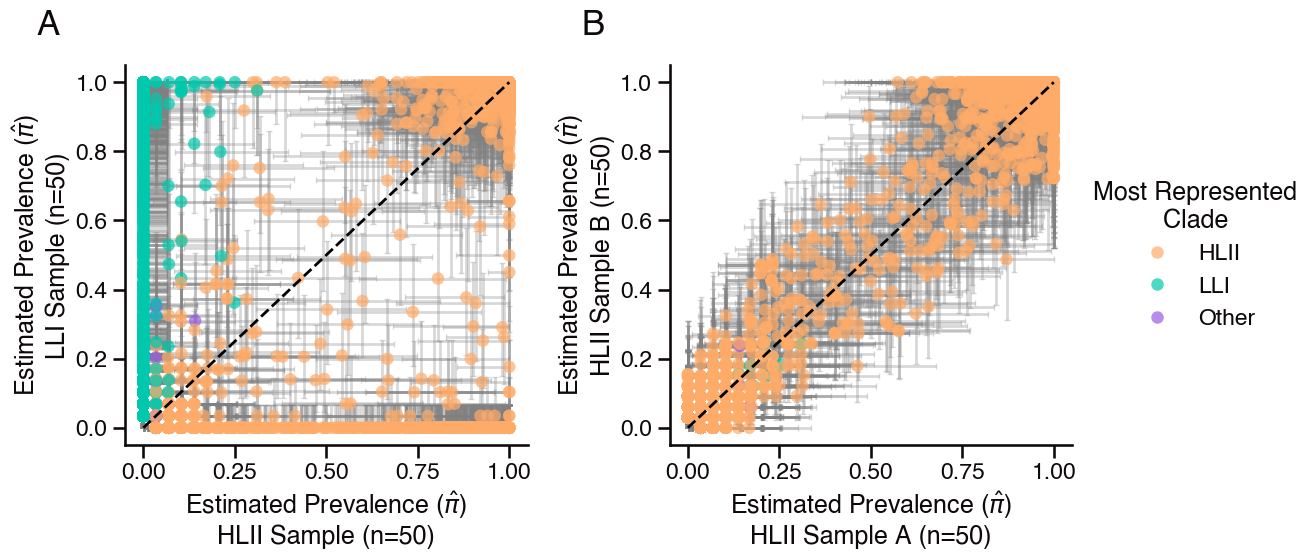

In [5]:
# build two panel figure that shows cross-clade comparison of pi hat estimates versus 
# within-clade comparison of pi hat estimates

# annotation specs
annotation_kwargs = dict(
    xy=(-0.22, 1.08),
    xycoords='axes fraction',
    fontsize=25,
    fontweight='bold'
)

# make figure
fig, axes = plt.subplots(1, 2, figsize=(13.5, 6))

# simplify most represented clade labels for legend
most_repped_clade[~most_repped_clade.isin(['HLII', 'LLI'])] = 'Other'
color_mapping = {
    'HLII': palette[1],
    'LLI': palette[2],
    'Other': palette[0]
}

# plot A: pi hat estimates from mixed pro population, colored by most represented clade
cross_clade_df['most_repped_clade'] = most_repped_clade.loc[cross_clade_df.index]
sns.scatterplot(
    data=cross_clade_df,
    x='pi_hat_A',
    y='pi_hat_B',
    hue='most_repped_clade',
    hue_order=['HLII', 'LLI', 'Other'],
    palette=color_mapping,
    ax=axes[0],
    edgecolor='none',
    alpha=0.7,
    legend=False,
)
axes[0].plot([0, 1], [0, 1], ls='--', color='black', zorder=2)
axes[0].set_xlabel(f"Estimated Prevalence ({r'$\hat{\pi}$'})\nHLII Sample (n={sample_size})")
axes[0].set_ylabel(f"Estimated Prevalence ({r'$\hat{\pi}$'})\nLLI Sample (n={sample_size})")
# add error bars 
axes[0].errorbar(
    x=cross_clade_df["pi_hat_A"],
    y=cross_clade_df["pi_hat_B"],
    xerr=[cross_clade_df["pi_hat_A"] - cross_clade_df["ci_lower_A"], 
          cross_clade_df["ci_upper_A"] - cross_clade_df["pi_hat_A"]],
    yerr=[cross_clade_df["pi_hat_B"] - cross_clade_df["ci_lower_B"], 
          cross_clade_df["ci_upper_B"] - cross_clade_df["pi_hat_B"]],
    fmt="none",
    ecolor="gray",
    capsize=2,
    alpha=0.3,
    zorder=0,  # put error bars behind points
)
# annotate panel A
axes[0].annotate("A", **annotation_kwargs)

# plot B: pi hat estimates from two independent samples from the same clade
within_clade_df['most_repped_clade'] = most_repped_clade.loc[within_clade_df.index]
sns.scatterplot(
    data=within_clade_df,
    x='pi_hat_A',
    y='pi_hat_B',
    hue='most_repped_clade',
    hue_order=['HLII', 'LLI', 'Other'],
    palette=color_mapping,
    edgecolor='none',
    alpha=0.7,
    legend=True,
    ax=axes[1],
)
axes[1].plot([0, 1], [0, 1], ls='--', color='black', zorder=2)
axes[1].set_xlabel(f"Estimated Prevalence ({r'$\hat{\pi}$'})\nHLII Sample A (n={sample_size})")
axes[1].set_ylabel(f"Estimated Prevalence ({r'$\hat{\pi}$'})\nHLII Sample B (n={sample_size})")
# add legend for panel B
axes[1].legend(title="Most Represented\n          Clade", loc='center left', bbox_to_anchor=(1, 0.5))
# add error bars
axes[1].errorbar(
    x=within_clade_df["pi_hat_A"],
    y=within_clade_df["pi_hat_B"],
    xerr=[within_clade_df["pi_hat_A"] - within_clade_df["ci_lower_A"], 
          within_clade_df["ci_upper_A"] - within_clade_df["pi_hat_A"]],
    yerr=[within_clade_df["pi_hat_B"] - within_clade_df["ci_lower_B"], 
          within_clade_df["ci_upper_B"] - within_clade_df["pi_hat_B"]],
    fmt="none",
    ecolor="gray",
    capsize=2,
    alpha=0.3,
    zorder=0,  # put error bars behind points
)
# annotate panel B
axes[1].annotate("B", **annotation_kwargs)

# adjust layout and save figure
plt.tight_layout()
# plt.savefig("demonstration_experiments.png", bbox_inches='tight')
plt.show()


### Value add of method

- saturation curves to show how many new gene clusters are added with each new genome
- evaluation of change in CI widths with numbers of genomes sampled

In [6]:
# build saturation curve for each subset of genomes

# build lists of complete, incomplete, and all genomes
complete_genomes = genome_metadata_df.loc[genome_metadata_df['complete'], 'genome'].tolist()
incomplete_genomes = genome_metadata_df.loc[~genome_metadata_df['complete'], 'genome'].tolist()
all_genomes = genome_metadata_df['genome'].tolist()

# shuffle the lists of genomes to randomize the order in which they are added to the saturation curve
rng.shuffle(complete_genomes)
rng.shuffle(incomplete_genomes)
rng.shuffle(all_genomes)

# iterate through the lists of genomes and calculate the number of new gene clusters
# observed with the addition of each genome to the saturation curve
results = []
for i in range(1, len(all_genomes) + 1):
    for subset_name, genome_list in zip(
        ['complete', 'incomplete', 'all'],
        [complete_genomes, incomplete_genomes, all_genomes]
    ):
        if i > len(genome_list):
            continue
        subset_genomes = genome_list[:i]
        subset_pa_df = pa_df.loc[subset_genomes]
        n_genomes = len(subset_genomes)
        n_gene_clusters = (subset_pa_df.sum(axis=0) > 0).sum()
        results.append({
            'subset': subset_name,
            'n_genomes': n_genomes,
            'n_gene_clusters': n_gene_clusters
        })

saturation_df = pd.DataFrame(results)
saturation_df

,subset,n_genomes,n_gene_clusters
0,complete,1,2531
1,incomplete,1,1422
2,all,1,643
3,complete,2,3436
4,incomplete,2,1784
...,...,...,...
2193,all,1095,52369
2194,all,1096,52418
2195,all,1097,52424
2196,all,1098,52464


In [7]:
# evaluate how confidence interval width changes with increasing sample size for each subset of genomes

# set sample sizes to evaluate
sample_sizes = [
    # 1, 10, 20, 65, 100, 500, 1000, 1034, 1099, 
    1, 5, 10, 20, 30, 40, 50, 60, 65, 
    70, 80, 100, 200, 300, 400, 500, 
    600, 700, 800, 900, 1000, 1034, 1099
]

# iterate through sample sizes and subsets, fit Bernoulli prevalence model, and calculate confidence interval widths
results = []
for subset_name, genome_list in zip(
    ['complete', 'incomplete', 'all'],
    [complete_genomes, incomplete_genomes, all_genomes]
):
    for sample_size in sample_sizes:
        if sample_size > len(genome_list):
            continue
        print(f"Fitting model for subset '{subset_name}' with sample size {sample_size}...")
        subset_genomes = genome_list[:sample_size]
        subset_pa_df = pa_df.loc[subset_genomes]
        # fit prevalence model using true completeness levels as input
        model = BernoulliPrevalenceModel(
            data=subset_pa_df, 
            lambdas=completeness_series.loc[subset_genomes], 
            )
        fit = model.fit(
            estimator="mle",
            interval_method="likelihood_ratio",
            alpha=ci_alpha,
            clip=True
        )
        pi_hat = fit.prevalence
        ci_lower, ci_upper = fit.confidence_interval()
        ci_widths = ci_upper - ci_lower
        results.append({
            'subset': subset_name,
            'sample_size': sample_size,
            'mean_ci_width': ci_widths.mean(),
            'std_ci_width': ci_widths.std(),
            'core_size': (pi_hat == 1.0).sum(),  # number of gene clusters with estimated prevalence of 1.0
            'expanded_core_size': ((pi_hat >= 0.9)).sum(),  # number of gene clusters with estimated prevalence of 0.9 or higher
            'alt_expanded_core_size': ((ci_upper >= 1.0).sum())  # number of gene clusters with upper confidence interval bound that includes 1.0
        })

ci_width_df = pd.DataFrame(results)
ci_width_df

Fitting model for subset 'complete' with sample size 1...
Fitting model for subset 'complete' with sample size 5...
Fitting model for subset 'complete' with sample size 10...
Fitting model for subset 'complete' with sample size 20...
Fitting model for subset 'complete' with sample size 30...
Fitting model for subset 'complete' with sample size 40...
Fitting model for subset 'complete' with sample size 50...
Fitting model for subset 'complete' with sample size 60...
Fitting model for subset 'complete' with sample size 65...
Fitting model for subset 'incomplete' with sample size 1...
Fitting model for subset 'incomplete' with sample size 5...
Fitting model for subset 'incomplete' with sample size 10...
Fitting model for subset 'incomplete' with sample size 20...
Fitting model for subset 'incomplete' with sample size 30...
Fitting model for subset 'incomplete' with sample size 40...
Fitting model for subset 'incomplete' with sample size 50...
Fitting model for subset 'incomplete' with sam

,subset,sample_size,mean_ci_width,std_ci_width,core_size,expanded_core_size,alt_expanded_core_size
0,complete,1,0.853581,0.000018,2531,2531,2531
1,complete,5,0.339483,0.083947,1187,1187,1187
2,complete,10,0.199120,0.082775,952,1185,952
3,complete,20,0.115276,0.071227,901,953,901
4,complete,30,0.083652,0.061944,891,941,891
5,complete,40,0.066863,0.054342,881,934,881
6,complete,50,0.057267,0.050008,871,936,871
7,complete,60,0.050102,0.046353,869,936,869
8,complete,65,0.047408,0.045062,869,935,869
9,incomplete,1,0.996032,0.023782,1422,1422,52500


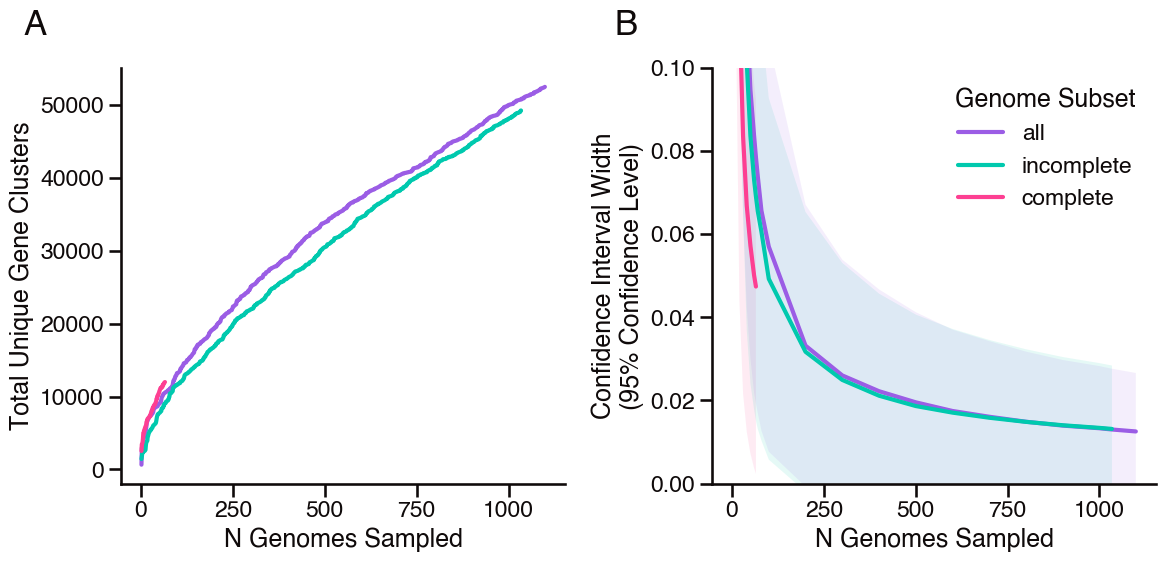

In [14]:
# build two panel figure showing (A) saturation curves for each subset of genomes and 
# (B) how confidence interval width changes with increasing sample size for each subset of genomes

# set up figure and axes
fig, axes = plt.subplots(1, 2, figsize=(12, 6))

# annotation specs
annotation_kwargs = dict(
    xy=(-0.22, 1.08),
    xycoords='axes fraction',
    fontsize=25,
    fontweight='bold'
)

# plot A: saturation curves
sns.lineplot(
    data=saturation_df,
    x="n_genomes",
    y="n_gene_clusters",
    hue="subset",
    hue_order=['all', 'incomplete', 'complete'],
    palette=[palette[i] for i in [0, 2, 3]],
    linewidth=3,
    ax=axes[0], 
    legend=False
)
axes[0].set_xlabel("N Genomes Sampled")
axes[0].set_ylabel("Total Unique Gene Clusters")
# add annotation for panel A
axes[0].annotate("A", **annotation_kwargs)

# plot B: confidence interval widths
sns.lineplot(
    data=ci_width_df[ci_width_df['sample_size'].ge(10)],
    x="sample_size",
    y="mean_ci_width",
    hue="subset",
    hue_order=['all', 'incomplete', 'complete'],
    palette=[palette[i] for i in [0, 2, 3]],
    linewidth=3,
    ax=axes[1]
)
# add color bands to represent one standard deviation around the mean confidence interval width for each subset
for subset_name, color in zip(['complete', 'incomplete', 'all'], [palette[i] for i in [3, 2, 0]]):
    subset_df = ci_width_df[ci_width_df['subset'] == subset_name]
    axes[1].fill_between(
        x=subset_df['sample_size'],
        y1=subset_df['mean_ci_width'] - subset_df['std_ci_width'],
        y2=subset_df['mean_ci_width'] + subset_df['std_ci_width'],
        color=color,
        alpha=0.1,
        zorder=0
    )
axes[1].set_xlabel("N Genomes Sampled")
axes[1].set_ylabel(f"Confidence Interval Width\n({(1 - ci_alpha) * 100:.0f}% Confidence Level)")
axes[1].set_ylim(0, 0.1)
axes[1].legend(title="Genome Subset")
# add annotation for panel B
axes[1].annotate("B", **annotation_kwargs)

# save and show the figure
plt.tight_layout()
# plt.savefig("ci_width_saturation_curves.png", dpi=300)
plt.show()